# A proposed Black Box simulator, explained

*Marcus Washington: a proposal to Group 5*

**What this is.** A walk-through of the simulator I built for the SSIE 501 Black Box: the 20×20 grid of digits 0–9 that changes every time you click **Next**. I'm proposing it to the group as our model of the hidden rule. The code is my current version, split into small pieces with comments added. The rule itself is unchanged; a separate test confirmed this notebook produces exactly the same grids as the original file.

**How to read it.** You don't need to read Python. The text cells explain what each region does and why. Every code cell starts with a comment line saying what it's for, and the comments walk through each step. In Google Colab, use *Runtime → Run all*. Run the cells top to bottom, because later cells use things built in earlier ones.

**Cell labels** follow our ELN: letters **A–T are columns** and numbers **1–20 are rows**, so M1 is row 1, column M. Every label this notebook prints uses that convention.

**One step = one click of Next** (with n = 1). Each step updates the four regions in a fixed order: R1, then R2, then R3, then R4. Each region picks one cell at random (R4 picks a pair) and applies its own rule. Because the regions take turns, a later region already sees whatever an earlier one changed in the same step.

| Section | What it covers |
|---|---|
| 1 | The grid, the four regions, and neighbors |
| 2 | R1: counter cells driven by logic gates |
| 3 | R2: multiply (FO part) and minimum (PT part) |
| 4 | R3: fresh random values from a fixed table |
| 5 | R4: swaps that please the neighbors |
| 6 | Putting it together: the `Sim` class |
| 7 | Demo on a made-up start grid |
| 8 | Connecting to what we saw in the ELN |

## 1. The grid and the four regions

The page shows digits 0–9. The simulator also allows **out-of-range** values (10 or more); the page shows those with no color.

**Box numbers.** The computer stores the grid as one list of 400 boxes, numbered 0–399 row by row: row 1 is boxes 0–19, row 2 is boxes 20–39, and so on. Inside the code, rows and columns are counted **from 0** (a Python habit), so code row 0 is ELN row 1 and code column 0 is column A. The helper `eln()` below converts code positions to ELN labels, so you never have to do it in your head.

**Blocks.** The grid divides into sixteen 5×5 blocks, numbered 0–15 left to right, top to bottom. Block 0 is A1:E5 and block 15 is P16:T20. Each region is four blocks, 100 cells:

| Region | Cells (ELN) | Blocks |
|---|---|---|
| R1 | rows 1–5, A–O, plus rows 6–10, A–E | 0, 1, 2, 4 |
| R2 | rows 1–5, P–T, plus rows 6–10, F–T | 3, 5, 6, 7 |
| R3 | rows 11–15, A–O, plus rows 16–20, A–E | 8, 9, 10, 12 |
| R4 | rows 11–15, P–T, plus rows 16–20, F–T | 11, 13, 14, 15 |

R2 has two sub-parts that follow different rules:
- **PT**: columns P–T, rows 1–10 (blocks 3 and 7, 50 cells)
- **FO**: columns F–O, rows 6–10 (blocks 5 and 6, 50 cells)

**Moore neighbors.** A cell's Moore neighbors are the 8 cells touching it: up, down, left, right, and the four diagonals. There's **no wrap-around**, so a cell on the edge just has fewer neighbors (a corner cell has 3 and an edge cell has 5). A neighbor can sit in a different region. R4 uses neighbors (Section 5).

In [ ]:
# Build the fixed layout of the grid: which region each cell belongs to, the two parts of R2, and every cell's neighbors.
# Nothing here is random. It is the "map" that the rules in later sections work on.
import numpy as np

N = 20                                   # the grid is N x N = 20 x 20 = 400 cells

# REG holds a region number for every cell: 0 = R1, 1 = R2, 2 = R3, 3 = R4.
REG = np.zeros((N, N), dtype=int)
# _BR maps each block's place in the 4x4 layout of blocks, as (block-row, block-column) counted from 0, to its region.
_BR = {(0, 0): 0, (0, 1): 0, (0, 2): 0, (1, 0): 0, (0, 3): 1, (1, 1): 1, (1, 2): 1, (1, 3): 1,
       (2, 0): 2, (2, 1): 2, (2, 2): 2, (3, 0): 2, (2, 3): 3, (3, 1): 3, (3, 2): 3, (3, 3): 3}
for (br, bc), k in _BR.items():
    REG[br*5:(br+1)*5, bc*5:(bc+1)*5] = k     # paint that whole 5x5 block with region number k

# PT = columns P-T of rows 1-10 (code rows 0-9, code columns 15-19). FO = the rest of R2 (rows 6-10, columns F-O).
PT = np.zeros((N, N), bool); PT[0:10, 15:20] = True
FO = (REG == 1) & ~PT

# Lists of box numbers (0-399) for each region, so a rule can pick a random cell of a region by picking from its list.
R_CELLS = [np.flatnonzero(REG.ravel() == k) for k in range(4)]   # R_CELLS[0] = the 100 R1 boxes, R_CELLS[1] = R2, ...
FO_CELLS = np.flatnonzero(FO.ravel())                             # the 50 FO boxes
PT_SET = set(np.flatnonzero(PT.ravel()).tolist())                 # the 50 PT boxes, stored as a set for quick "is it PT?" checks

# The 8 directions to a Moore neighbor, as (row change, column change). (0, 0) is the cell itself, so it is skipped.
OFF8 = [(dr, dc) for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr, dc) != (0, 0)]


def moore_nowrap(i):
    """Box numbers of the Moore neighbors of box i, leaving out any that would fall off the grid (no wrap-around)."""
    r, c = divmod(i, N)                  # box number -> (code row, code column)
    return [(r + dr) * N + (c + dc) for dr, dc in OFF8 if 0 <= r + dr < N and 0 <= c + dc < N]


NB8 = [moore_nowrap(i) for i in range(N * N)]    # NB8[i] = neighbor list of box i, worked out once up front
# Leftover, unused: neighbor lists limited to R1 cells (an older R1 rule used them). Kept so the code matches the original.
NB8_R1 = [[j for j in NB8[i] if REG.flat[j] == 0] for i in range(N * N)]

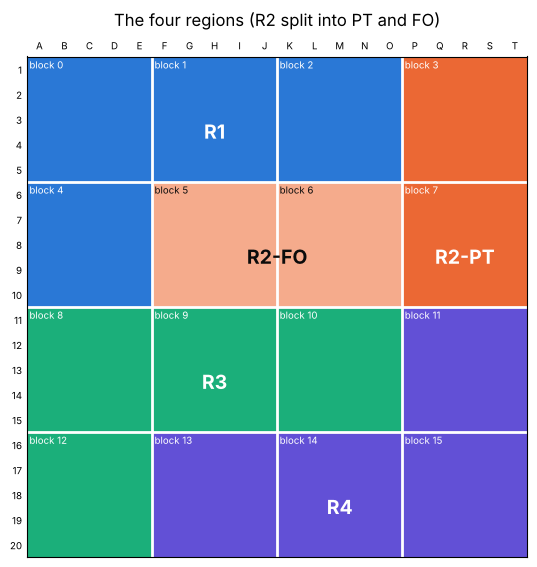

In [ ]:
# Helpers that turn code positions into ELN labels, then a labeled picture of the regions and blocks.
# (Display only: nothing in this cell is part of the rule.)
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

COLS = "ABCDEFGHIJKLMNOPQRST"

def eln(r, c):
    """ELN label for code row r and code column c (both counted from 0). Example: eln(0, 12) -> 'M1'."""
    return f"{COLS[c]}{r + 1}"

def eln_box(i):
    """ELN label for box number i (0-399). Example: eln_box(12) -> 'M1'."""
    return eln(*divmod(int(i), N))

def region_name(i):
    """Region of box i in words, with R2 split into its PT and FO parts."""
    k = REG.flat[i]
    if k == 1:
        return "R2-PT" if i in PT_SET else "R2-FO"
    return f"R{k + 1}"

def eln_axes(ax):
    """Label a grid picture like the ELN: columns A-T along the top, rows 1-20 down the side, row 1 at the top."""
    ax.set_xticks(range(N)); ax.set_xticklabels(list(COLS), fontsize=7)
    ax.set_yticks(range(N)); ax.set_yticklabels(range(1, N + 1), fontsize=7)
    ax.xaxis.tick_top(); ax.tick_params(length=0)

# One color per region. FO gets a lighter shade of R2's orange because it is part of R2.
PART = REG.copy(); PART[PT] = 1; PART[FO] = 4        # 0 = R1, 1 = R2-PT, 2 = R3, 3 = R4, 4 = R2-FO
REGION_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#f5ab8c"]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(PART, cmap=ListedColormap(REGION_COLOURS), vmin=-0.5, vmax=4.5)
eln_axes(ax)
for x in np.arange(4.5, N - 1, 5):                    # thin white lines between the 5x5 blocks
    ax.axvline(x, color="white", lw=2); ax.axhline(x, color="white", lw=2)
for b in range(16):                                   # block numbers in each block's top-left corner
    r0, c0 = (b // 4) * 5, (b % 4) * 5
    ax.text(c0 - 0.4, r0 - 0.4, f"block {b}", fontsize=7, ha="left", va="top",
            color="#0b0b0b" if PART[r0, c0] == 4 else "white")
for name, (r, c) in {"R1": (2.5, 7), "R2-PT": (7.5, 17), "R2-FO": (7.5, 9.5), "R3": (12.5, 7), "R4": (17.5, 12)}.items():
    ax.text(c, r, name, fontsize=14, fontweight="bold", ha="center", va="center",
            color="#0b0b0b" if name == "R2-FO" else "white")
ax.set_title("The four regions (R2 split into PT and FO)", pad=22)
plt.show()

## 2. R1: counter cells driven by logic gates

**Low half, high half.** R1 splits the digits into two halves: **low = 0–4** and **high = 5–9**. Within its half, a cell ticks toward the middle. Low cells count up 0→1→2→3→4, and high cells count down 9→8→7→6→5. A 4 or a 5 has nowhere further to go, so it stays put.

**What one R1 update does:**
1. Pick one of the 100 R1 cells by a *uniform random pick*: every cell is equally likely, like drawing a name from a hat.
2. If the cell holds an out-of-range value (10 or more), do nothing.
3. Ask the cell's **gate** which half it *should* be in. That answer is the cell's *target*: HIGH or LOW.
4. If the target is the other half, the cell **jumps** to the far end of that half: high → 0, low → 9.
5. If the cell is already in its target half, it **ticks** one step toward the middle. A 4 or a 5 doesn't move.

Our ELN shows both kinds of move. M1 went 0→1 and A5 went 7→6 (ticks), and E5 went 7→0 (a jump).

**Gates.** The target isn't random. It's the output of a fixed yes/no rule, a *logic gate*, that checks whether a few specific *source cells* are currently LOW or HIGH. A gate reads each input as its band: 0 for LOW (0–4) and 1 for HIGH (5 and up). It combines inputs with three Boolean words:
- **AND**: HIGH only if *both* inputs are HIGH.
- **OR**: HIGH if *at least one* input is HIGH.
- **NOT**: flips the input, so NOT LOW = HIGH and NOT HIGH = LOW.

In the code, HIGH = 1 and LOW = 0. `a & b` means AND, `a | b` means OR, and `1 - a` means NOT.

**Where the gates look.** R1 is made of blocks 0, 1, 2 and 4. All four blocks use the same 25 gate formulas, one for each position in the block. What differs from block to block is where the inputs come from:
- **Source block.** Most inputs are cells of a *source block*. Blocks 0, 1 and 4 read themselves. Block 2 (K1:O5) reads block 0 (A1:E5).
- **Outside center cells.** Three gates also read the center cell of a block outside R1. These inputs are called `cp`, `cq` and `c_0`. The check cell after the code prints exactly which cells they are. Through these inputs, R1 depends on the other regions.

**Positions are counted from 0 inside a block.** Gate position (i, j) means row i, column j *within the 5×5 block*, counting from 0. (0, 0) is the block's top-left cell and (4, 4) is its bottom-right. "Source (2, 0)" means the source block's cell in its 3rd row, 1st column.

**Worked example.** Gate (0, 0) says *"wants HIGH when source (2, 0) is LOW"*.
- In block 0, position (0, 0) is **A1** and source (2, 0) is **A3**. A1's target is HIGH whenever A3 shows 0–4. Say A1 shows 2. If A3 shows 7, the target is LOW; A1 is already low, so it ticks to 3. If A3 shows 1 instead, the target is HIGH, so A1 jumps to 9.
- In block 2, position (0, 0) is **K1**. Block 2's source is block 0, so K1 *also* listens to **A3**.

**Out-of-range and unknown inputs.** The code treats these two cases differently:
- **Out of range (10+).** A source cell holding 10 or more reads as **HIGH**, because the band test only asks "is it 5 or more?".
- **Unknown (negative).** A negative number counts as unknown (band −1). Any gate with an unknown input outputs −1, which means "no opinion: stay in your current half," so the cell just ticks. This path was written for logged grids where a color couldn't be read. Inside the simulator it never runs. The simulator turns start-grid negatives into 10 (Section 6), and no rule ever produces a negative number.

In [ ]:
# R1's wiring: which blocks feed which, plus the 25 gate formulas that set each R1 cell's target half.
# These functions only read the grid. They never change a cell and never use random numbers.

# CORNER[b] = (code row, code column) of block b's top-left cell. Block b sits at block-row b // 4, block-column b % 4.
CORNER = {b: ((b // 4) * 5, (b % 4) * 5) for b in range(16)}
# SRC_BLOCK[b] = the block whose cells feed R1 block b's gates. Blocks 0, 1, 4 read themselves; block 2 reads block 0.
SRC_BLOCK = {0: 0, 1: 1, 2: 0, 4: 4}
# SIGMA[b] = the block whose center cell is c_0 for R1 block b (read by gate (3, 3)).
SIGMA = {0: 7, 1: 10, 2: 15, 4: 11}
# CENTRES[b] = the two blocks whose center cells are cp and cq for R1 block b (read by gates (1, 1) and (1, 2)).
CENTRES = {0: (5, 6), 1: (8, 9), 2: (13, 14), 4: (3, 12)}

def _band(v):
    """A value's band: 0 = LOW (0-4), 1 = HIGH (5 or more, so out-of-range 10 counts as HIGH), -1 = unknown (negative)."""
    return -1 if v < 0 else int(v >= 5)

def a_target_map(g, b):
    """Target half for all 25 cells of R1 block b, read from the 20x20 grid g: 1 = HIGH, 0 = LOW, -1 = no opinion."""
    # s = the bands of the 25 cells of the source block. S(i, j) reads one of them (position counted from 0).
    sr, sc = CORNER[SRC_BLOCK[b]]
    s = np.array([[_band(g[sr + i, sc + j]) for j in range(5)] for i in range(5)])
    # k(...) asks "are all these inputs known (none is -1)?". A gate only answers when all of its inputs are known.
    def k(*v): return all(x >= 0 for x in v)
    # cell(blk, i, j) = band of the cell at position (i, j) of block blk. Block numbers wrap around past 15 (% 16).
    def cell(blk, i, j):
        blk %= 16; return _band(g[(blk // 4) * 5 + i, (blk % 4) * 5 + j])
    S = lambda i, j: s[i, j]; sg = SIGMA[b]
    # c_0 = band of the center cell of block SIGMA[b]. c_m2 and c_m1 are leftover, unused (from an earlier gate search).
    c_m2, c_m1, c_0 = cell(sg - 2, 2, 2), cell(sg - 1, 2, 2), cell(sg, 2, 2)
    r34_m3 = cell(sg - 3, 3, 4)          # leftover, unused
    # cp, cq = bands of the center cells of the two blocks listed in CENTRES[b]. Both sit outside R1.
    cp, cq = cell(CENTRES[b][0], 2, 2), cell(CENTRES[b][1], 2, 2)
    # The 25 gates. Each key is a position in the block (row, column), counted from 0. "src (i,j)" = the source-block
    # cell at (i, j). Most lines read "(formula) if k(inputs) else -1": answer only when every input is known.
    rules = {
        # (0,0) wants HIGH when src (2,0) is LOW
        (0, 0): lambda: (1 - S(2, 0)) if k(S(2, 0)) else -1,
        # (0,1) wants HIGH when src (0,4) is HIGH AND src (0,2) is LOW
        (0, 1): lambda: (S(0, 4) & (1 - S(0, 2))) if k(S(0, 4), S(0, 2)) else -1,
        # (0,2) wants HIGH when src (2,1) is HIGH (a plain copy; an unknown input passes straight through as -1)
        (0, 2): lambda: S(2, 1),
        # (0,3) wants HIGH when src (4,1) is HIGH AND src (3,4) is LOW
        (0, 3): lambda: (S(4, 1) & (1 - S(3, 4))) if k(S(4, 1), S(3, 4)) else -1,
        # (0,4) wants HIGH when at least one of src (0,3), (1,1), (1,2) is HIGH, AND src (4,2) is LOW
        (0, 4): lambda: ((S(0, 3) | S(1, 1) | S(1, 2)) & (1 - S(4, 2))) if k(S(0, 3), S(1, 1), S(1, 2), S(4, 2)) else -1,
        # (1,0) wants HIGH when src (1,4) is HIGH (a plain copy)
        (1, 0): lambda: S(1, 4),
        # (1,1) wants HIGH when outside center cells cp AND cq are both HIGH
        (1, 1): lambda: (cp & cq) if k(cp, cq) else -1,
        # (1,2) wants HIGH when src (3,3) is HIGH AND outside center cell cp is HIGH
        (1, 2): lambda: (S(3, 3) & cp) if k(S(3, 3), cp) else -1,
        # (1,3) wants HIGH when src (3,0) is HIGH (a plain copy)
        (1, 3): lambda: S(3, 0),
        # (1,4) wants HIGH when src (0,1) OR src (2,0) is HIGH
        (1, 4): lambda: (S(0, 1) | S(2, 0)) if k(S(0, 1), S(2, 0)) else -1,
        # (2,0) wants HIGH when src (3,1) is HIGH AND src (0,2) is LOW
        (2, 0): lambda: (S(3, 1) & (1 - S(0, 2))) if k(S(3, 1), S(0, 2)) else -1,
        # (2,1) wants HIGH when src (1,3) is HIGH AND src (0,3) is LOW
        (2, 1): lambda: (S(1, 3) & (1 - S(0, 3))) if k(S(1, 3), S(0, 3)) else -1,
        # (2,2) wants HIGH when src (0,0) is LOW
        (2, 2): lambda: (1 - S(0, 0)) if k(S(0, 0)) else -1,
        # (2,3) wants HIGH when src (0,4) is LOW AND at least one of src (1,1), (3,3) is HIGH
        (2, 3): lambda: ((1 - S(0, 4)) & (S(1, 1) | S(3, 3))) if k(S(0, 4), S(1, 1), S(3, 3)) else -1,
        # (2,4) wants HIGH when src (2,3) is HIGH (a plain copy)
        (2, 4): lambda: S(2, 3),
        # (3,0) wants HIGH when src (2,3) AND src (4,3) are both HIGH
        (3, 0): lambda: (S(2, 3) & S(4, 3)) if k(S(2, 3), S(4, 3)) else -1,
        # (3,1) wants HIGH when src (2,1) is LOW AND at least one of src (2,0), (2,4) is HIGH
        (3, 1): lambda: ((1 - S(2, 1)) & (S(2, 0) | S(2, 4))) if k(S(2, 1), S(2, 0), S(2, 4)) else -1,
        # (3,2) wants HIGH when src (1,4) is HIGH (a plain copy)
        (3, 2): lambda: S(1, 4),
        # (3,3) wants HIGH when outside center cell c_0 is HIGH (a plain copy)
        (3, 3): lambda: c_0,
        # (3,4) wants HIGH when src (2,1) is HIGH AND src (3,2) is LOW
        (3, 4): lambda: (S(2, 1) & (1 - S(3, 2))) if k(S(2, 1), S(3, 2)) else -1,
        # (4,0) wants HIGH when src (0,3) is HIGH (a plain copy)
        (4, 0): lambda: S(0, 3),
        # (4,1) wants HIGH when src (0,0) AND src (1,0) are both HIGH, AND src (3,4) is LOW
        (4, 1): lambda: (S(0, 0) & S(1, 0) & (1 - S(3, 4))) if k(S(0, 0), S(1, 0), S(3, 4)) else -1,
        # (4,2) wants HIGH when src (2,1) is HIGH (a plain copy)
        (4, 2): lambda: S(2, 1),
        # (4,3) wants HIGH when src (3,2) is LOW AND at least one of src (2,1), (4,3) is HIGH
        (4, 3): lambda: ((1 - S(3, 2)) & (S(2, 1) | S(4, 3))) if k(S(3, 2), S(2, 1), S(4, 3)) else -1,
        # (4,4) wants HIGH when src (2,1) is HIGH (a plain copy)
        (4, 4): lambda: S(2, 1),
    }
    T = np.full((5, 5), -1, int)                      # start every position at -1 ("no opinion")
    for (i, j), f in rules.items(): T[i, j] = f()     # then fill in each gate's answer
    return T

In [ ]:
# R1's update for one step: pick one R1 cell, get its target half from its gate, then jump or tick.
def r1_update(self):
    """R1 step. Section 6 plugs this in as the Sim class's _r1 method (self = the running simulation)."""
    g, rng = self.g, self.rng            # g = the grid as 400 boxes; rng = the random-number generator
    i = R_CELLS[0][rng.integers(100)]    # uniform random pick of one of the 100 R1 boxes
    v = g[i]                             # its current value
    if v > 9:                            # out of range (10+): R1 leaves it alone
        return
    r, c = divmod(i, N)                  # box number -> code row and column
    b = (r // 5) * 4 + c // 5            # which block (0-15) the cell is in
    # a_target_map works out all 25 targets of the block; (r % 5, c % 5) is this cell's position inside its block.
    T = int(a_target_map(g.reshape(N, N), b)[r % 5, c % 5])
    high = v >= 5                        # is the cell in the high half right now?
    if T < 0:                            # gate has no opinion (an input was unknown): target = the current half
        T = int(high)
    if T != int(high):                   # wrong half: jump to the far end of the other half
        g[i] = 0 if high else 9
    elif v <= 3:                         # right half, low side, not yet 4: tick up one
        g[i] = v + 1
    elif v >= 6:                         # right half, high side, not yet 5: tick down one
        g[i] = v - 1
    # otherwise v is 4 or 5: already in the right half and at the middle, so it stays

In [ ]:
# Check the R1 explanation by running the real code: list the cells each R1 block's gates read, then replay the worked example.
import types

def span(blk):
    """ELN range of a block, for example block 0 -> 'A1:E5'."""
    r0, c0 = CORNER[blk]; return f"{eln(r0, c0)}:{eln(r0 + 4, c0 + 4)}"

def centre(blk):
    """ELN label of a block's center cell, with the region it sits in."""
    r0, c0 = CORNER[blk]; i = (r0 + 2) * N + c0 + 2; return f"cell {eln_box(i)} (in {region_name(i)})"

for b in (0, 1, 2, 4):
    print(f"R1 block {b} ({span(b)}): source block {SRC_BLOCK[b]} ({span(SRC_BLOCK[b])}); "
          f"cp = {centre(CENTRES[b][0])}, cq = {centre(CENTRES[b][1])}, c_0 = {centre(SIGMA[b])}")

# Worked example. Fill a grid with 2s, so A1 holds 2, then try A3 = 7 (HIGH), 1 (LOW) and 10 (out of range).
# A stand-in random generator always "picks" A1, so r1_update itself makes the move described in the text.
class AlwaysA1:
    def integers(self, n): return 0      # position 0 in the R1 list is box 0, which is A1

print()
for a3 in (7, 1, 10):
    grid = np.full((N, N), 2); grid[2, 0] = a3                 # code row 2, column 0 is A3
    t_a1, t_k1 = a_target_map(grid, 0)[0, 0], a_target_map(grid, 2)[0, 0]
    demo = types.SimpleNamespace(g=grid.ravel().copy(), rng=AlwaysA1())
    r1_update(demo)
    print(f"A3 = {a3:>2}: A1 wants {'HIGH' if t_a1 else 'LOW'}, K1 wants {'HIGH' if t_k1 else 'LOW'}; "
          f"R1 moves A1 from 2 to {demo.g[0]}")
print(f"\n_band(10) = {_band(10)} (out of range reads HIGH);  _band(-1) = {_band(-1)} (unknown)")

R1 block 0 (A1:E5): source block 0 (A1:E5); cp = cell H8 (in R2-FO), cq = cell M8 (in R2-FO), c_0 = cell R8 (in R2-PT)
R1 block 1 (F1:J5): source block 1 (F1:J5); cp = cell C13 (in R3), cq = cell H13 (in R3), c_0 = cell M13 (in R3)
R1 block 2 (K1:O5): source block 0 (A1:E5); cp = cell H18 (in R4), cq = cell M18 (in R4), c_0 = cell R18 (in R4)
R1 block 4 (A6:E10): source block 4 (A6:E10); cp = cell R3 (in R2-PT), cq = cell C18 (in R3), c_0 = cell R13 (in R4)

A3 =  7: A1 wants LOW, K1 wants LOW; R1 moves A1 from 2 to 3
A3 =  1: A1 wants HIGH, K1 wants HIGH; R1 moves A1 from 2 to 9
A3 = 10: A1 wants LOW, K1 wants LOW; R1 moves A1 from 2 to 3

_band(10) = 1 (out of range reads HIGH);  _band(-1) = -1 (unknown)


## 3. R2: multiply (FO part) and minimum (PT part)

R2 picks one of its 100 cells by a uniform random pick; call its value **v**. It then picks a **partner** cell at random and reads its value **n**. Where the partner can come from, and what happens next, depends on the sub-part:

- **PT part** (columns P–T, rows 1–10). The partner is a uniform random pick from **rows 11–20**: the whole bottom half, which means R3 and R4 in any column. The new value is **min(v, n)**, the smaller of the two. A PT cell can only stay the same or go down, and once it reaches 0 it stays 0.
- **FO part** (columns F–O, rows 6–10). The partner is a uniform random pick from the **FO part itself**, and it can be the cell itself. The new value is **(v × n) mod 10**. *Mod 10* means keep only the last digit: 7 × 8 = 56 → 6, and 3 × 9 = 27 → 7. Anything times 0 is 0, so 0 sticks here too. An out-of-range value (10) times anything ends in 0, so FO turns a 10 into a 0.

The ELN changes fit these rules. N9 went 4→8 (FO: a partner of 2 gives 4 × 2 = 8) and L8 went 3→7 (FO: a partner of 9 gives 27 → 7). T1 went 7→3 (PT: the minimum of 7 and a partner of 3).

In [ ]:
# R2's update for one step: pick one R2 cell and combine it with a randomly picked partner cell.
def r2_update(self):
    """R2 step. Section 6 plugs this in as the Sim class's _r2 method."""
    g, rng = self.g, self.rng
    i = R_CELLS[1][rng.integers(100)]          # uniform random pick of one of the 100 R2 boxes
    v = g[i]                                   # its current value
    if i in PT_SET:                            # PT part (columns P-T):
        n = g[N * 10 + rng.integers(N * 10)]   #   partner = a random box from 200-399, i.e. rows 11-20, any column
        g[i] = min(v, n)                       #   keep the smaller of the two values
    else:                                      # FO part (rows 6-10, columns F-O):
        n = g[FO_CELLS[rng.integers(len(FO_CELLS))]]   # partner = a random FO box (it may be the cell itself)
        g[i] = (v * n) % 10                    #   multiply, then keep only the last digit ("mod 10")

## 4. R3: fresh random values from a fixed table

R3 ignores the grid entirely. Each step it picks one of its 100 cells by a uniform random pick and overwrites it with a fresh digit drawn from a fixed **probability table** called **PI**. The table lists the chance of each outcome, and all the chances add up to 1. Small digits are far more likely than large ones: **0 comes up about 36% of the time** and 1 about 33%, while 9 is rare. The last entry is the chance of an out-of-range draw, which the simulator writes as 10.

The new digit doesn't depend on the old one. Sometimes R3 redraws the value a cell already had, and the ELN would record that as no change. F12 (3→2) and N12 (2→3) in our ELN are R3 cells.

The settings dictionary `DEFAULT` is defined here because PI is the main setting it holds. It also holds `q0`, which is used once at start-up only to keep the random numbers lined up (Section 6), plus some leftovers from earlier model versions that the v3 rule never reads.

In [ ]:
# The model's settings (PI is the one R3 uses), then R3's update: overwrite one random R3 cell with a fresh draw from PI.
DEFAULT = {
    # q0: used once at start-up to draw numbers that are then thrown away (kept so the random numbers line up; Section 6).
    "q0": 0.374,
    # Leftover, unused: settings from earlier R1/R4 versions. The current rule never reads them.
    "w": 0.408, "q_lo": 0.115, "q_hi": 0.270, "rho_t": 0.00028, "rho_4": 0.0, "kappa": 0.0244, "pc": 0.0588,
    # PI: R3's probability table. Entry k = chance of drawing digit k (k = 0..9); the last entry = chance of out of range.
    "PI": [0.3568, 0.3331, 0.1743, 0.0733, 0.0332, 0.0146, 0.0076, 0.0041, 0.0020, 0.0008, 0.0002],
    "oor_values": [10],          # the value written for an out-of-range draw
}


def r3_update(self):
    """R3 step. Section 6 plugs this in as the Sim class's _r3 method."""
    g, rng = self.g, self.rng
    i = R_CELLS[2][rng.integers(100)]           # uniform random pick of one of the 100 R3 boxes
    k = rng.choice(len(self.PI), p=self.PI)     # weighted random draw: outcome k (0-10) comes up with chance PI[k]
    # Outcomes 0-9 are written as that digit. Outcome 10 means out of range: write a value from oor_values (here, 10).
    g[i] = k if k < 10 else self.p["oor_values"][rng.integers(len(self.p["oor_values"]))]

In [ ]:
# Show R3's probability table PI as value -> probability, scaled to add up to 1 exactly as the simulator does.
pi_table = np.array(DEFAULT["PI"], float); pi_table /= pi_table.sum()
print(f"{'value':>18} -> probability")
for value, p in enumerate(pi_table):
    label = str(value) if value < 10 else "out of range (10)"
    print(f"{label:>18} -> {p:6.2%}  {'#' * round(p * 100)}")     # each # is about one percentage point
print(f"\n0 is drawn {pi_table[0]:.1%} of the time; 0 or 1 together {pi_table[0] + pi_table[1]:.1%}.")

             value -> probability
                 0 -> 35.68%  ####################################
                 1 -> 33.31%  #################################
                 2 -> 17.43%  #################
                 3 ->  7.33%  #######
                 4 ->  3.32%  ###
                 5 ->  1.46%  #
                 6 ->  0.76%  #
                 7 ->  0.41%  
                 8 ->  0.20%  
                 9 ->  0.08%  
 out of range (10) ->  0.02%  

0 is drawn 35.7% of the time; 0 or 1 together 69.0%.


## 5. R4: swaps that please the neighbors

R4 never creates or destroys a value; it only **swaps** two of its own cells. So the number of 0s, 1s, 2s and so on in R4 never changes.

1. If all 100 R4 cells hold the same value, there's nothing to swap, so skip.
2. Pick two R4 cells at random. If they turn out to be the same cell, or they hold the same value, throw the pick away and pick again. Keep going until the pick is two different cells with different values. This "draw, check, redraw until it passes" method is called **rejection sampling**. It gives every qualifying pair the same chance.
3. **Count before.** For each of the two cells, count how many of its Moore neighbors hold the same value it does. Neighbors can be in any region.
4. **Swap and count after.** Swap the two values, then count again: how many neighbors now match each cell's new value?
5. **Accept or undo.** Keep the swap only if *neither* cell ends up with fewer matching neighbors *and* at least one ends up with more. Otherwise, swap back.

Every accepted swap adds matching neighbors, so over time R4 drifts toward patches of equal values. Most attempted swaps get undone.

In [ ]:
# R4's update for one step: pick two R4 cells with different values and swap them only if the neighbors approve.
def same_count(self, i, val):
    """How many Moore neighbors of box i currently hold the value val. Section 6 plugs this in as Sim's _same method."""
    g = self.g
    return sum(1 for j in NB8[i] if g[j] == val)


def r4_update(self):
    """R4 step. Section 6 plugs this in as the Sim class's _r4 method."""
    g, rng = self.g, self.rng
    cells = R_CELLS[3]                         # the 100 R4 boxes
    vals = g[cells]                            # their current values (a copy, taken before anything moves)
    if np.all(vals == vals[0]):                # every R4 cell holds the same value: no valid pair exists
        return
    # Rejection sampling: draw two positions in the R4 list, and redraw until they are different cells with different values.
    while True:
        a, b = rng.integers(100, size=2)
        if a != b and vals[a] != vals[b]:
            break
    i, j = cells[a], cells[b]                  # the two chosen boxes
    vi, vj = g[i], g[j]                        # their values
    bi, bj = self._same(i, vi), self._same(j, vj)   # matching neighbors BEFORE the swap
    g[i], g[j] = vj, vi                        # try the swap
    ai, aj = self._same(i, vj), self._same(j, vi)   # matching neighbors AFTER (each cell now holds the other's value)
    # Keep the swap only if neither cell lost matches and together they gained at least one; otherwise swap back.
    if not (ai >= bi and aj >= bj and (ai + aj) > (bi + bj)):
        g[i], g[j] = vi, vj

## 6. Putting it together: the `Sim` class

`Sim` holds one running simulation: the grid, a random-number generator, and the settings. It plugs in the four region rules from Sections 2–5.

- **Seed.** A computer's "random" numbers come from a generator that starts from a number called the *seed*. The same seed produces the same sequence of random picks every time, so a run can be repeated exactly. A different seed gives a different run.
- **Start-up.** `Sim` copies the start grid and turns any negative value (our marker for "couldn't read this color") into 10, i.e. out of range. Then it draws 100 random numbers that the rule never uses; an older R1 used them as hidden targets, and v3 doesn't. The draw still has to stay. Taking it out would shift every random pick that follows, and the runs would no longer match the original simulator.
- **`step()`** is one click of Next: R1, R2, R3, R4, in that order.
- **`run(n)`** runs n steps and keeps a copy of the grid after each one. Copy 0 is the start grid, and copy t is the grid after step t.

In [ ]:
# The simulator: it holds the grid, the random generator and the settings, and runs steps.
class Sim:
    def __init__(self, grid0, seed, params=None):
        self.p = dict(DEFAULT)                       # start from the default settings...
        if params:
            self.p.update(params)                    # ...and override any that were passed in
        self.rng = np.random.default_rng(seed)       # the random generator: same seed -> same run
        self.g = np.array(grid0, dtype=int).ravel().copy()   # a private copy of the grid, as 400 boxes
        self.g[self.g < 0] = 10                      # unknown color in a start grid -> out of range
        r1 = R_CELLS[0]
        # Kept so the random numbers line up with the original; not used by the rule (an old R1 version's hidden targets).
        self.target_high = np.zeros(N * N, bool)
        self.target_high[r1] = self.rng.random(len(r1)) < self.p["q0"]
        self.PI = np.array(self.p["PI"], float); self.PI /= self.PI.sum()   # R3's table, scaled to add up to exactly 1

    # The four region rules from Sections 2-5, plugged in as this class's methods.
    _r1 = r1_update
    _r2 = r2_update
    _r3 = r3_update
    _same = same_count
    _r4 = r4_update

    def step(self):
        """One click of Next: update R1, then R2, then R3, then R4 (each sees the changes made before it)."""
        self._r1(); self._r2(); self._r3(); self._r4()

    def run(self, nsteps):
        """Run nsteps steps and return every grid as one array: out[0] = start, out[t] = the grid after step t."""
        out = np.empty((nsteps + 1, N, N), dtype=int)
        out[0] = self.g.reshape(N, N)
        for t in range(1, nsteps + 1):
            self.step()
            out[t] = self.g.reshape(N, N)
        return out

## 7. Demo on a made-up start grid

**This is not the real Reset screen.** The start grid below is 400 digits 0–9 drawn at random (seed 501), just to give the simulator something to run on. Nothing in this section depends on the real page.

First we run 3 steps and list every cell that changed, laid out like the step 77→80 tables in our ELN (Cell, From, To, Δ), plus the region that made the change. Then we run a few hundred steps and compare the grid before and after.

In [ ]:
# Build the made-up start grid, run 3 steps, and print each step's changed cells ELN-style (Cell, From, To, Δ).
START_SEED, RUN_SEED = 501, 2026
start = np.random.default_rng(START_SEED).integers(0, 10, size=(N, N))   # MADE-UP start grid: random digits 0-9
sim = Sim(start, seed=RUN_SEED)
before = sim.g.copy()
for t in range(1, 4):
    sim.step()
    after = sim.g.copy()
    changed = np.flatnonzero(after != before)          # boxes whose value differs from the previous step
    print(f"Step {t - 1} -> {t}    # Cells Changed: {len(changed)}    Matrix Total: {before.sum()} -> {after.sum()}")
    print(f"  {'Cell':<6}{'From':>5}{'To':>5}{'Δ':>5}   Region")
    for i in changed:
        print(f"  {eln_box(i):<6}{before[i]:>5}{after[i]:>5}{after[i] - before[i]:>+5}   {region_name(i)}")
    print(f"  {'Total':<6}{before[changed].sum():>5}{after[changed].sum():>5}{(after[changed] - before[changed]).sum():>+5}\n")
    before = after

Step 0 -> 1    # Cells Changed: 3    Matrix Total: 1837 -> 1830
  Cell   From   To    Δ   Region
  N5        7    0   -7   R1
  Q9        6    5   -1   R2-PT
  N11       0    1   +1   R3
  Total    13    6   -7

Step 1 -> 2    # Cells Changed: 2    Matrix Total: 1830 -> 1837
  Cell   From   To    Δ   Region
  O1        1    9   +8   R1
  L9        7    6   -1   R2-FO
  Total     8   15   +7

Step 2 -> 3    # Cells Changed: 3    Matrix Total: 1837 -> 1838
  Cell   From   To    Δ   Region
  G3        1    2   +1   R1
  M8        9    8   -1   R2-FO
  C13       0    1   +1   R3
  Total    10   11   +1



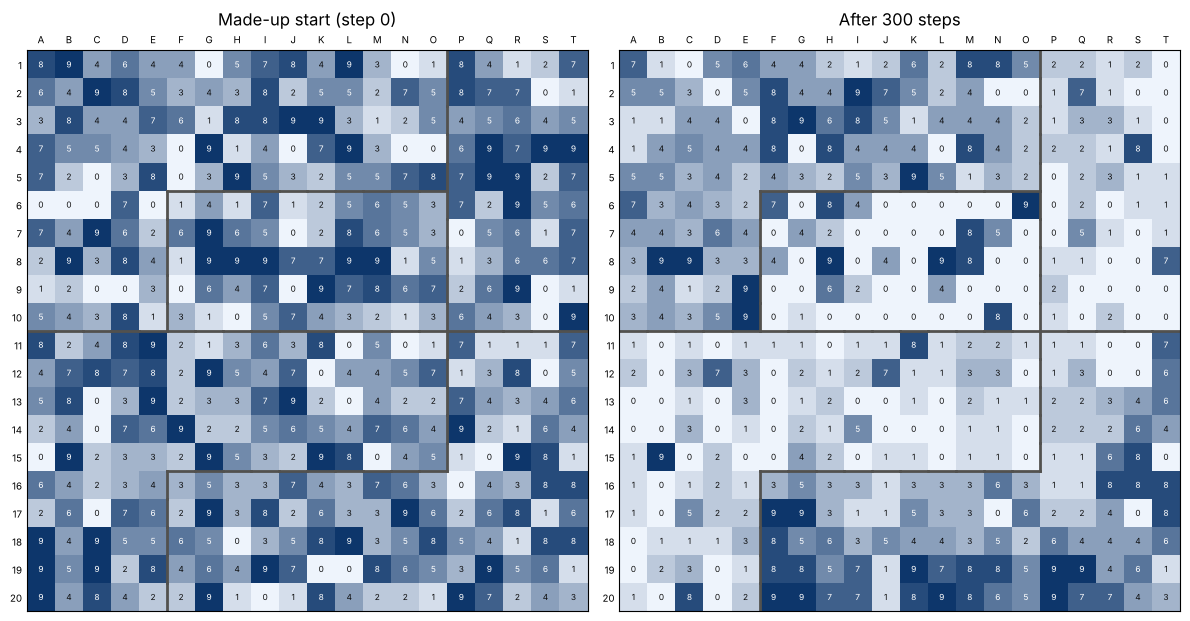

   R1:  81 of 100 cells differ from the start after 300 steps
R2-PT:  38 of 50 cells differ from the start after 300 steps
R2-FO:  42 of 50 cells differ from the start after 300 steps
   R3:  89 of 100 cells differ from the start after 300 steps
   R4:  54 of 100 cells differ from the start after 300 steps


In [ ]:
# Re-run the same demo (same start grid, same seed) for 300 steps and draw the grid at the start and at the end.
from matplotlib.colors import LinearSegmentedColormap

STEPS_B = 300
traj = Sim(start, seed=RUN_SEED).run(STEPS_B)        # traj[0] = start, traj[300] = after step 300

digits = LinearSegmentedColormap.from_list("digits", ["#eef4fc", "#0d366b"], N=10)   # 0 = lightest blue, 9 = darkest
digits.set_bad("white")                                                                # out of range (10+): no color

def draw_grid(ax, grid, title):
    """Heatmap of one grid with its digits written in, the region borders outlined, and ELN axis labels."""
    ax.imshow(np.ma.masked_where(grid >= 10, grid), cmap=digits, vmin=-0.5, vmax=9.5)
    for r in range(N):
        for c in range(N):
            ax.text(c, r, grid[r, c], ha="center", va="center", fontsize=6,
                    color="white" if 5 <= grid[r, c] <= 9 else "#0b0b0b")
            # region borders: draw a line wherever two touching cells belong to different parts
            if c + 1 < N and PART[r, c] != PART[r, c + 1]:
                ax.plot([c + 0.5, c + 0.5], [r - 0.5, r + 0.5], color="#52514e", lw=2)
            if r + 1 < N and PART[r, c] != PART[r + 1, c]:
                ax.plot([c - 0.5, c + 0.5], [r + 0.5, r + 0.5], color="#52514e", lw=2)
    eln_axes(ax); ax.set_title(title, pad=18)

fig, axes = plt.subplots(1, 2, figsize=(12, 6.4))
draw_grid(axes[0], traj[0], "Made-up start (step 0)")
draw_grid(axes[1], traj[-1], f"After {STEPS_B} steps")
plt.tight_layout(); plt.show()

moved = traj[-1] != traj[0]                          # cells whose value differs from the start
for name, code_ in [("R1", 0), ("R2-PT", 1), ("R2-FO", 4), ("R3", 2), ("R4", 3)]:
    print(f"{name:>5}: {moved[PART == code_].sum():3d} of {(PART == code_).sum()} cells differ from the start after {STEPS_B} steps")

## 8. Connecting to what we saw in the ELN

Every number in this section is printed by the code in the cell that computes it. The runs use the made-up start from the demo. The real page started from a different grid, so look for the same *pattern*, not the same counts.

**(a) How many cells change per step.** Each region touches at most one cell per step, except R4, which moves two when a swap is accepted. Many picks change nothing at all. An R1 cell already at 4 or 5 stays put, an R2 product or minimum can equal the old value, R3 can redraw the same digit, and R4 undoes most of its swaps. The cells that do change in one step come from different regions, so they are almost never Moore neighbors. The exceptions are an R4 swap between two touching cells, or two cells that happen to sit on either side of a region border. Our ELN tables show this: in each step, the changed cells land in different regions.

In [ ]:
# (a) Over 2,000 steps from the made-up start: how many cells change per step, which regions change them,
#     and how often two cells changed in the same step are Moore neighbors.
STEPS_A = 2000
run_a = Sim(start, seed=RUN_SEED).run(STEPS_A)
diff = (run_a[1:] != run_a[:-1]).reshape(STEPS_A, -1)     # diff[t, i] is True if box i changed in step t + 1
n_changed = diff.sum(axis=1)

print(f"Cells changed per step, over {STEPS_A:,} steps:")
for n, count in enumerate(np.bincount(n_changed)):
    print(f"  {n} {'cell ' if n == 1 else 'cells'}: {count:5,d} steps ({count / STEPS_A:5.1%})")

reg = REG.ravel()
per_region = np.stack([diff[:, reg == k].sum(axis=1) for k in range(4)], axis=1)   # cells changed per step, per region
print()
for k in range(4):
    print(f"  R{k + 1} changed a cell in {np.mean(per_region[:, k] > 0):5.1%} of steps; "
          f"most cells it changed in one step: {per_region[:, k].max()}")

# Neighbor check: in steps where 2+ cells changed, does any pair of changed cells touch (Moore neighbors)?
multi = touching = same_region = across_border = 0
for t in np.flatnonzero(n_changed >= 2):
    boxes = np.flatnonzero(diff[t])
    pairs = [(a, b) for a in boxes for b in boxes if a < b and b in NB8[a]]
    multi += 1
    touching += bool(pairs)
    same_region += any(reg[a] == reg[b] for a, b in pairs)      # only R4 can change two cells in one region
    across_border += any(reg[a] != reg[b] for a, b in pairs)
print(f"\nSteps with 2+ changed cells: {multi:,}. Steps where two changed cells touch: {touching} ({touching / multi:.1%}).")
print(f"  Of those, an R4 swap of two touching cells: {same_region}; two cells touching across a region border: {across_border}.")

Cells changed per step, over 2,000 steps:
  0 cells:   362 steps (18.1%)
  1 cell : 1,140 steps (57.0%)
  2 cells:   338 steps (16.9%)
  3 cells:   121 steps ( 6.0%)
  4 cells:    25 steps ( 1.2%)
  5 cells:    14 steps ( 0.7%)

  R1 changed a cell in 25.8% of steps; most cells it changed in one step: 1
  R2 changed a cell in 10.0% of steps; most cells it changed in one step: 1
  R3 changed a cell in 74.6% of steps; most cells it changed in one step: 1
  R4 changed a cell in  3.5% of steps; most cells it changed in one step: 2

Steps with 2+ changed cells: 498. Steps where two changed cells touch: 9 (1.8%).
  Of those, an R4 swap of two touching cells: 8; two cells touching across a region border: 1.


In [ ]:
# Our ELN's own tables from the real page (steps 77 -> 80): which region each changed cell sits in, and whether the
# change fits that region's rule.
eln_tables = {"77 -> 78": [("M1", 0, 1), ("N9", 4, 8), ("F12", 3, 2)],
              "78 -> 79": [("E5", 7, 0), ("N12", 2, 3), ("T1", 7, 3)],
              "79 -> 80": [("A5", 7, 6), ("L8", 3, 7)]}

def box(label):
    """ELN label -> box number. Example: 'M1' -> 12."""
    return (int(label[1:]) - 1) * N + COLS.index(label[0])

def fits_rule(part, a, b):
    """Could this region's rule turn a into b in one step?"""
    if part == "R1":                     # a jump to the far end of the other half, or a tick toward the middle
        return b == (0 if a >= 5 else 9) or (a <= 3 and b == a + 1) or (a >= 6 and b == a - 1)
    if part == "R2-FO":                  # some partner digit n gives (a x n) mod 10 = b
        return any((a * n) % 10 == b for n in range(10))
    if part == "R2-PT":                  # a minimum can only go down
        return b < a
    return part == "R3"                  # R3 can draw any digit; an R4 change would need its swap partner to check

for step, rows in eln_tables.items():
    parts = [region_name(box(label)) for label, a, b in rows]
    cells = ", ".join(f"{label} {a}->{b} {p} ({'fits' if fits_rule(p, a, b) else 'does NOT fit'})"
                      for (label, a, b), p in zip(rows, parts))
    regions = {p[:2] for p in parts}     # R2-PT and R2-FO both count as R2
    print(f"Step {step}: {cells}.  Every cell in a different region: {len(regions) == len(rows)}")

Step 77 -> 78: M1 0->1 R1 (fits), N9 4->8 R2-FO (fits), F12 3->2 R3 (fits).  Every cell in a different region: True
Step 78 -> 79: E5 7->0 R1 (fits), N12 2->3 R3 (fits), T1 7->3 R2-PT (fits).  Every cell in a different region: True
Step 79 -> 80: A5 7->6 R1 (fits), L8 3->7 R2-FO (fits).  Every cell in a different region: True


**(b) Zeros pile up.** Several rules push the grid toward 0, and the next cell counts the zeros in each region over the same run:
- R3 draws 0 more often than any other digit (see the PI table above), so its zero count should hover near PI's chance of 0 times the number of R3 cells.
- R2 treats 0 as a dead end. In PT, min(0, n) is always 0, and PT's partners come from rows 11–20, where R3 keeps supplying zeros. In FO, 0 × n is always 0.
- R4 only swaps, so its zero count never changes.
- R1 makes a 0 only by jumping down from the high half, and then ticks it back up toward 4.

Early in the ELN we wrote that the matrix "coalesces with 0 at a diagonal pattern in center (LL:UR)". R2 (the upper-right L shape) and R3 (the lower-left L shape) together form a band from lower left to upper right. Compare the "after" heatmap in the demo above.

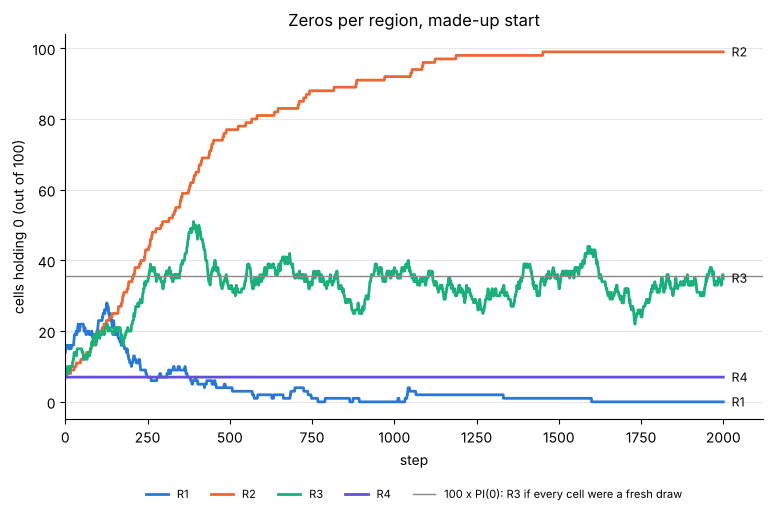

Whole grid: 38 zeros at the start, 141 after step 2,000.
R3: averages 33.1 zeros over steps 1,000-2,000; 100 x PI(0) = 35.7.
R2: 8 -> 99 zeros (PT 4 -> 49 of 50, FO 4 -> 50 of 50).
R4: between 7 and 7 zeros at every step (swaps never change the count).
R1: 14 -> 0 zeros.


In [ ]:
# (b) Count the cells holding 0 at every step of the 2,000-step run from (a), region by region, and compare R3 with PI.
zeros = (run_a == 0).reshape(STEPS_A + 1, -1)                       # zeros[t, i] is True if box i holds 0 after step t
z = {f"R{k + 1}": zeros[:, reg == k].sum(axis=1) for k in range(4)}  # zero count per region at every step
pt_z, fo_z = zeros[:, PT.ravel()].sum(axis=1), zeros[:, FO.ravel()].sum(axis=1)
r3_expected = 100 * pi_table[0]                                     # zeros R3 would hold if every cell were a fresh PI draw

fig, ax = plt.subplots(figsize=(9, 5))
for k, (name, series) in enumerate(z.items()):
    ax.plot(series, color=REGION_COLOURS[k], lw=2, label=name)
    ax.text(STEPS_A + 25, series[-1], name, va="center", fontsize=9, color="#0b0b0b")   # direct label at the line's end
ax.axhline(r3_expected, color="#8a8984", lw=1, label="100 x PI(0): R3 if every cell were a fresh draw")
ax.set_xlabel("step"); ax.set_ylabel("cells holding 0 (out of 100)"); ax.set_xlim(0, STEPS_A * 1.06)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e8e7e3"); ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, fontsize=8)
ax.set_title("Zeros per region, made-up start"); plt.show()

late = slice(STEPS_A // 2, None)                                     # second half of the run
print(f"Whole grid: {zeros[0].sum()} zeros at the start, {zeros[-1].sum()} after step {STEPS_A:,}.")
print(f"R3: averages {z['R3'][late].mean():.1f} zeros over steps {STEPS_A // 2:,}-{STEPS_A:,}; "
      f"100 x PI(0) = {r3_expected:.1f}.")
print(f"R2: {z['R2'][0]} -> {z['R2'][-1]} zeros (PT {pt_z[0]} -> {pt_z[-1]} of 50, FO {fo_z[0]} -> {fo_z[-1]} of 50).")
print(f"R4: between {z['R4'].min()} and {z['R4'].max()} zeros at every step (swaps never change the count).")
print(f"R1: {z['R1'][0]} -> {z['R1'][-1]} zeros.")